# Retail Sales Analysis (EDA)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('retail_sales_dataset.csv')

In [3]:
df.head() # first 5 rows

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity          1000 non-null   int64 
 7   Price per Unit    1000 non-null   int64 
 8   Total Amount      1000 non-null   int64 
dtypes: int64(5), object(4)
memory usage: 70.4+ KB


In [5]:
# converting Date from object to datetime
df['Date'] = pd.to_datetime(df['Date']) 

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    1000 non-null   int64         
 1   Date              1000 non-null   datetime64[ns]
 2   Customer ID       1000 non-null   object        
 3   Gender            1000 non-null   object        
 4   Age               1000 non-null   int64         
 5   Product Category  1000 non-null   object        
 6   Quantity          1000 non-null   int64         
 7   Price per Unit    1000 non-null   int64         
 8   Total Amount      1000 non-null   int64         
dtypes: datetime64[ns](1), int64(5), object(3)
memory usage: 70.4+ KB


In [7]:
df.describe() # stats summary

,Transaction ID,Date,Age,Quantity,Price per Unit,Total Amount
count,1000.000000,1000,1000.00000,1000.000000,1000.000000,1000.000000
mean,500.500000,2023-07-03 00:25:55.200000256,41.39200,2.514000,179.890000,456.000000
min,1.000000,2023-01-01 00:00:00,18.00000,1.000000,25.000000,25.000000
25%,250.750000,2023-04-08 00:00:00,29.00000,1.000000,30.000000,60.000000
50%,500.500000,2023-06-29 12:00:00,42.00000,3.000000,50.000000,135.000000
75%,750.250000,2023-10-04 00:00:00,53.00000,4.000000,300.000000,900.000000
max,1000.000000,2024-01-01 00:00:00,64.00000,4.000000,500.000000,2000.000000
std,288.819436,NaN,13.68143,1.132734,189.681356,559.997632


In [8]:
df.shape

(1000, 9)

# Data Cleaning

In [9]:
# check missing values
df.isnull().sum()

Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

In [10]:
df.duplicated().sum()
# no duplicate records

np.int64(0)

In [11]:
df[["Age", "Quantity", "Price per Unit", "Total Amount"]]

,Age,Quantity,Price per Unit,Total Amount
0,34,3,50,150
1,26,2,500,1000
2,50,1,30,30
3,37,1,500,500
4,30,2,50,100
...,...,...,...,...
995,62,1,50,50
996,52,3,30,90
997,23,4,25,100
998,36,3,50,150


# sales analysis

In [12]:
# total revenue
revenue = df["Total Amount"].sum()

In [13]:
revenue

np.int64(456000)

In [14]:
# total transactions 
total_transactions = df['Transaction ID'].count()

In [15]:
total_transactions

np.int64(1000)

In [16]:
# total units sold
total_units_sold = df['Quantity'].sum()

In [17]:
total_units_sold

np.int64(2514)

In [18]:
# average transaction value
avg_tran_value = df['Total Amount'].mean()

In [19]:
avg_tran_value

np.float64(456.0)

In [20]:
# highest transaction
highest_transaction = df['Total Amount'].max()

In [21]:
highest_transaction

np.int64(2000)

In [22]:
# lowest transaction

In [23]:
lowest_transaction = df['Total Amount'].min()

In [24]:
lowest_transaction

np.int64(25)

# analyze product categories

In [25]:
# transactions per category
tran_per_cat = df.groupby('Product Category')['Total Amount'].count()

In [26]:
tran_per_cat

Product Category
Beauty         307
Clothing       351
Electronics    342
Name: Total Amount, dtype: int64

In [27]:
# revenue per category
rev_per_cat = df.groupby('Product Category')['Total Amount'].sum()

In [28]:
rev_per_cat

Product Category
Beauty         143515
Clothing       155580
Electronics    156905
Name: Total Amount, dtype: int64

In [29]:
# best performing category by revenue
rev_per_cat.max() # Electonics

np.int64(156905)

# analyze customer demographics

In [30]:
# transactions by gender
tran_per_gender = df.groupby('Gender')['Total Amount'].count()

In [31]:
tran_per_gender

Gender
Female    510
Male      490
Name: Total Amount, dtype: int64

In [32]:
# revenue per gender
rev_per_gender = df.groupby('Gender')['Total Amount'].sum()

In [33]:
rev_per_gender

Gender
Female    232840
Male      223160
Name: Total Amount, dtype: int64

# analysis of sales trends

In [34]:
# year and months from transaction dates
df['year'] = df['Date'].dt.year

In [35]:
df['month'] = df['Date'].dt.month

In [36]:
df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,year,month
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,2023,11
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,2023,2
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,2023,1
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,2023,5
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,2023,5


In [37]:
# monthly revenue
monthly_revenue = df.groupby('month')['Total Amount'].sum()

In [38]:
monthly_revenue

month
1     36980
2     44060
3     28990
4     33870
5     53150
6     36715
7     35465
8     36960
9     23620
10    46580
11    34920
12    44690
Name: Total Amount, dtype: int64

In [39]:
monthly_revenue.max() # the fifth month has the highest revenue

np.int64(53150)

In [40]:
monthly_revenue.min() # the 9th month has the lowest revenue

np.int64(23620)

# visuals

In [41]:
# revenue by category

In [42]:
rev_per_cat= df.groupby('Product Category')['Total Amount'].sum()

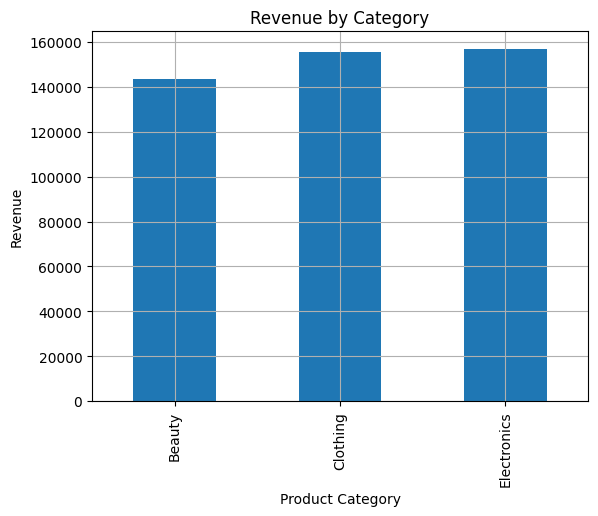

In [43]:
rev_per_cat.plot(kind='bar')
plt.ylabel('Revenue')
plt.title('Revenue by Category')
plt.grid()
plt.show()

In [54]:
# The Electronics product category holds highest appeal among customers

In [45]:
monthly_revenue = df.groupby('month')['Total Amount'].sum()

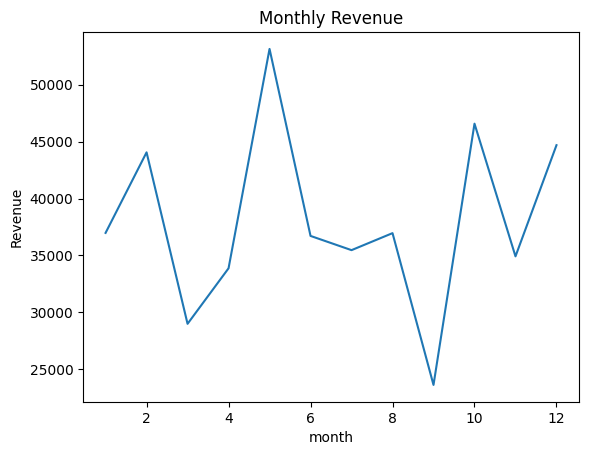

In [46]:
monthly_revenue.plot(kind='line')
plt.ylabel('Revenue')
plt.title('Monthly Revenue')
plt.show()

In [47]:
# Month May has the highest revenue and September month has the lowest revenue

In [48]:
# tansactions by gender
trans_by_gender = df.groupby('Gender')['Total Amount'].sum()

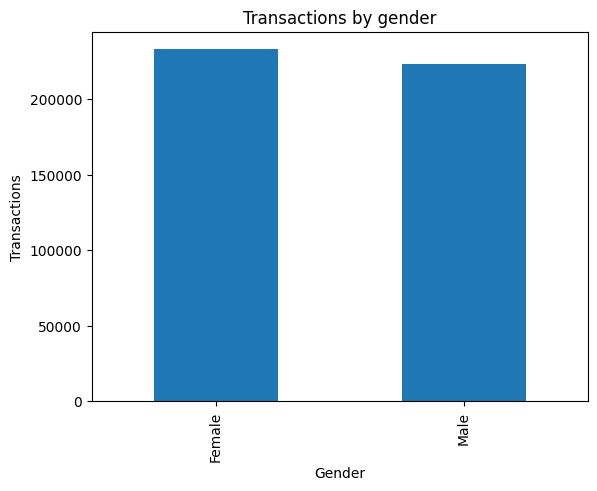

In [49]:
trans_by_gender.plot(kind='bar')
plt.ylabel("Transactions")
plt.title("Transactions by gender")
plt.show()

In [60]:
# female has the highest no of transactions than males

In [51]:
# revenue by age group
rev_by_age = df.groupby('Age')['Total Amount'].count()

[]

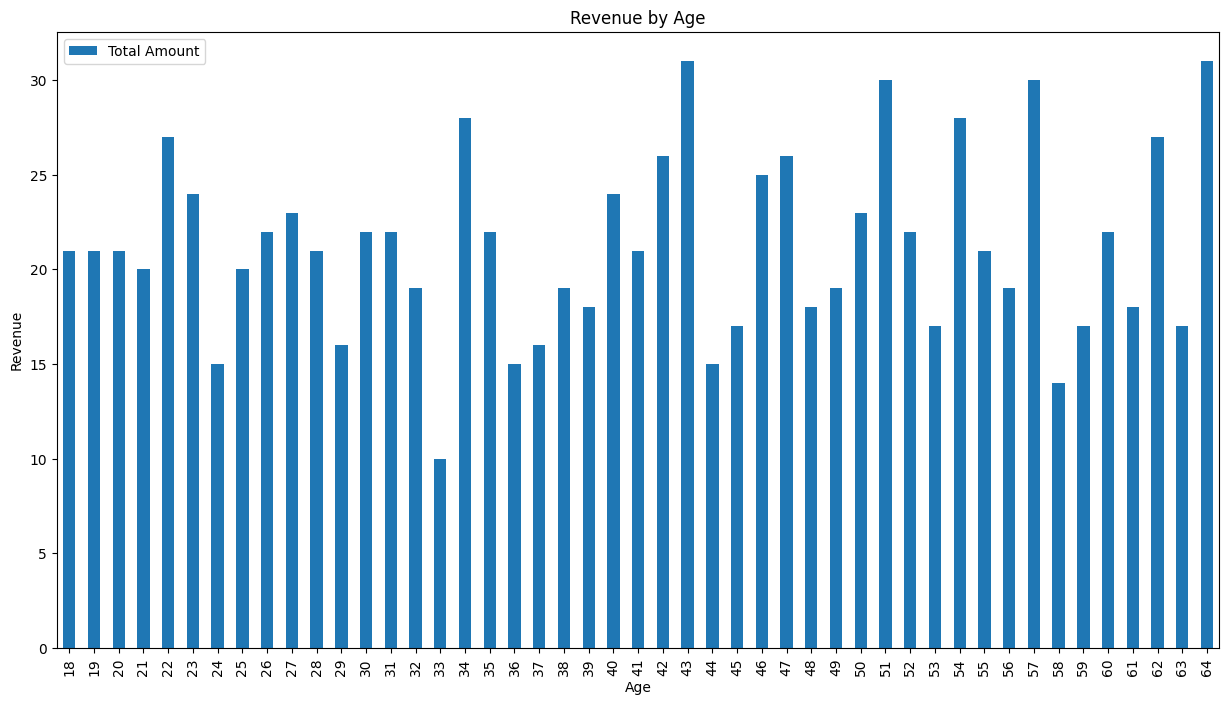

In [57]:
rev_by_age.plot(kind='bar', figsize=(15, 8))
# rev_by_age.plot()
plt.legend()
plt.ylabel('Revenue')
plt.title("Revenue by Age")
plt.plot()

In [59]:
# Customers aged 64 contribute the highest revenue, indicating higher purchasing expenditure, whereas customers aged 33 contribute the lowest revenue, indicating comparatively lower spending on products.